# Feature Engineering & Preprocessing Pipeline (leak-free)

**Task:** build a reusable scikit-learn pipeline for a credit-default problem that handles missing values, encoding, scaling and correlated features, then rank features, without leaking test information.

**Order of operations (the leak-prevention contract)**
1. Load, audit, **split first**.
2. Leakage and correlation screening on the **training set only**.
3. All learned statistics (medians, scaler means, category lists, target encodings, correlation drops) live **inside** one `Pipeline`, so they are re-fit on the training part of every CV fold.
4. Test set is touched once, at the end.

**Dataset.** By default this notebook generates a seeded synthetic credit-default table, so it runs offline and the answers are known: it has skewed numerics, redundant columns, informative missingness, a 40-level and a 500-level categorical, an ID, and one deliberately leaky column. Set `DATA_SOURCE = "openml_credit_g"` to run the same pipeline on the real German Credit data instead (needs internet; see the loader cell).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, StandardScaler,
                                   TargetEncoder, OrdinalEncoder)
from sklearn.utils.validation import check_is_fitted

SEED = 42
DATA_SOURCE = "synthetic"      # or "openml_credit_g"
pd.set_option("display.width", 140)

## 1. Load and audit the data

In [2]:
def make_credit_default(n=8000, seed=SEED):
    """Seeded synthetic credit-default data with realistic pitfalls."""
    rng = np.random.default_rng(seed)
    z = lambda v: (v - v.mean()) / v.std()
    age = np.clip(rng.normal(41, 12, n), 21, 75).round()
    income = rng.lognormal(10.9, 0.55, n).round(-2)
    months_employed = np.clip(rng.gamma(2.2, 30, n), 0, 480).round()
    loan_amount = (income * rng.uniform(0.1, 0.9, n)).round(-2)
    dti = rng.uniform(0.05, 0.45, n)
    monthly_debt = (income / 12 * dti).round()
    credit_limit = (income * rng.uniform(0.2, 0.8, n)).round(-2)
    utilization = np.clip(rng.beta(2, 3, n), 0, 1)
    total_balance = (credit_limit * utilization).round()
    open_accounts = rng.poisson(5, n)
    late_12m = rng.poisson(0.3 + 1.5 * utilization)
    monthly_income = (income / 12).round()                        # redundant export field
    education = rng.choice(["High school", "Bachelor", "Master", "PhD"], n, p=[.35, .4, .2, .05])
    home = rng.choice(["Rent", "Mortgage", "Own", "Other"], n, p=[.4, .35, .2, .05])
    purpose = rng.choice(["Car", "Home improvement", "Debt consolidation", "Education", "Medical", "Business"], n)
    region = rng.choice(["North", "South", "East", "West", "Central"], n)
    ind_eff = rng.normal(0, 0.4, 40)
    industry_id = rng.integers(0, 40, n)                          # 40 levels, real signal
    postal = rng.integers(0, 500, n)                              # 500 levels, pure noise
    purpose_eff = dict(zip(np.unique(purpose), rng.normal(0, .25, 6)))
    logit = (-2.45 + 0.9*z(late_12m) + 1.0*z(dti) + 0.7*z(utilization)
             - 0.5*z(np.log(income)) - 0.3*z(np.log1p(months_employed))
             + 0.4*(home == "Rent") + np.array([purpose_eff[p] for p in purpose])
             + ind_eff[industry_id] + 0.2*z(loan_amount/income))
    default = (rng.random(n) < 1/(1+np.exp(-logit))).astype(int)
    # LEAK: recorded 30 days AFTER the outcome, so unavailable at decision time
    collections = np.where(default == 1,
                           np.where(rng.random(n) < .92, "in_collections", "none"),
                           np.where(rng.random(n) < .02, "in_collections", "none"))
    df = pd.DataFrame(dict(customer_id=[f"C{i:05d}" for i in range(n)], age=age, income=income,
        monthly_income=monthly_income, loan_amount=loan_amount, monthly_debt=monthly_debt,
        debt_to_income=dti.round(3), credit_limit=credit_limit, credit_utilization=utilization.round(3),
        total_balance=total_balance, open_accounts=open_accounts, late_payments_12m=late_12m,
        months_employed=months_employed, education=education, home_ownership=home,
        loan_purpose=purpose, region=region, industry=[f"IND_{i:02d}" for i in industry_id],
        postal_prefix=[f"PC_{i:03d}" for i in postal],
        collections_status_30d_after=collections, default=default))
    # missingness: random, plus informative (defaulters hide employment history more often)
    miss = lambda p: rng.random(n) < p
    m_inc = miss(0.08); df.loc[m_inc, ["income", "monthly_income"]] = np.nan
    df.loc[miss(0.06 + 0.12*default), "months_employed"] = np.nan
    df.loc[miss(0.05), "credit_utilization"] = np.nan
    df.loc[miss(0.06), "education"] = np.nan
    df.loc[miss(0.03), "home_ownership"] = np.nan
    return df

def load_data(source=DATA_SOURCE):
    if source == "synthetic":
        df = make_credit_default()
        return df.drop(columns="default"), df["default"], ["customer_id", "collections_status_30d_after"]
    if source == "openml_credit_g":          # not run in the offline build of this notebook
        from sklearn.datasets import fetch_openml
        raw = fetch_openml("credit-g", version=1, as_frame=True, parser="auto").frame
        y = (raw.pop("class") == "bad").astype(int)
        rng = np.random.default_rng(SEED)    # German Credit has no NaNs: inject MCAR for the demo
        for c in raw.select_dtypes("number").columns:
            raw.loc[rng.random(len(raw)) < .05, c] = np.nan
        raw = raw.astype({c: object for c in raw.select_dtypes("category").columns})
        return raw, y, []
    raise ValueError(source)

X, y, KNOWN_NON_FEATURES = load_data()
print(X.shape, "| default rate:", round(y.mean(), 3))
audit = pd.DataFrame({"dtype": X.dtypes.astype(str), "n_unique": X.nunique(),
                      "missing_%": (X.isna().mean()*100).round(1)})
audit

(8000, 20) | default rate: 0.189


,dtype,n_unique,missing_%
customer_id,str,8000,0.0
age,float64,55,0.0
income,float64,1462,8.1
monthly_income,float64,1462,8.1
loan_amount,float64,1034,0.0
monthly_debt,float64,2849,0.0
debt_to_income,float64,401,0.0
credit_limit,float64,995,0.0
credit_utilization,float64,897,4.8
total_balance,float64,6822,0.0


## 2. Split **before** any transformation
Stratified so the default rate matches in both parts. For time-ordered data use a time-based split, and for repeated customers use `GroupShuffleSplit`.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, "| train rate", round(y_train.mean(), 3), "| test rate", round(y_test.mean(), 3))

(6400, 20) (1600, 20) | train rate 0.189 | test rate 0.189


## 3. Leakage screen (training set only)
Any column with suspiciously high dependence on the target, or that would not exist at decision time, is a leak candidate. Mutual information is computed on the **training** rows only.

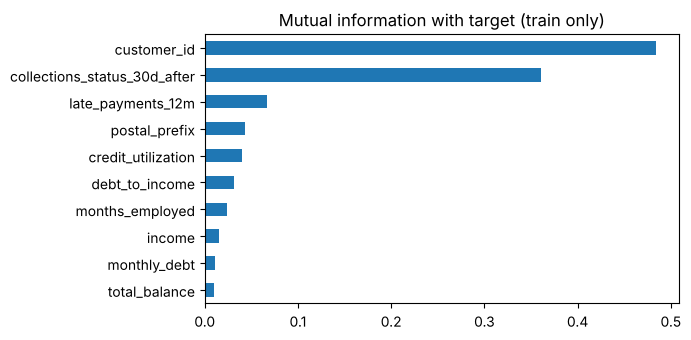

customer_id                     0.484405
collections_status_30d_after    0.360722
late_payments_12m               0.066792
postal_prefix                   0.043181
credit_utilization              0.039634
dtype: float64

In [4]:
def mi_screen(Xtr, ytr):
    enc = Xtr.copy()
    cat = [c for c in enc.columns if not pd.api.types.is_numeric_dtype(enc[c])]
    for c in cat: enc[c] = enc[c].fillna("Missing").astype(str)
    enc[cat] = OrdinalEncoder().fit_transform(enc[cat])
    enc = enc.fillna(enc.median(numeric_only=True))
    mi = mutual_info_classif(enc, ytr, discrete_features=[c in cat for c in enc.columns], random_state=SEED)
    return pd.Series(mi, index=enc.columns).sort_values(ascending=False)

screen = mi_screen(X_train, y_train)
ax = screen.head(10).iloc[::-1].plot.barh(figsize=(7, 3.5), title="Mutual information with target (train only)")
plt.tight_layout(); plt.show()
screen.head(5)

`collections_status_30d_after` has very high MI, and by name it is recorded **after** the outcome, so it is target leakage. `customer_id` scores highest only because a unique-per-row identifier lets MI memorise the training rows; it carries no real signal and would not generalise. Both go in an explicit drop list, and the preprocessor uses `remainder="drop"`, so any column not deliberately routed is excluded. Note also that the 500-level `postal_prefix` (pure noise here) scores above several genuine predictors: MI on high-cardinality columns is inflated by chance, a reason not to trust it alone.

In [5]:
LEAK_OR_ID = ["customer_id", "collections_status_30d_after"]   # decision: documented, not data-driven alone
assert set(KNOWN_NON_FEATURES) <= set(LEAK_OR_ID)

## 4. Correlation analysis (training set only)

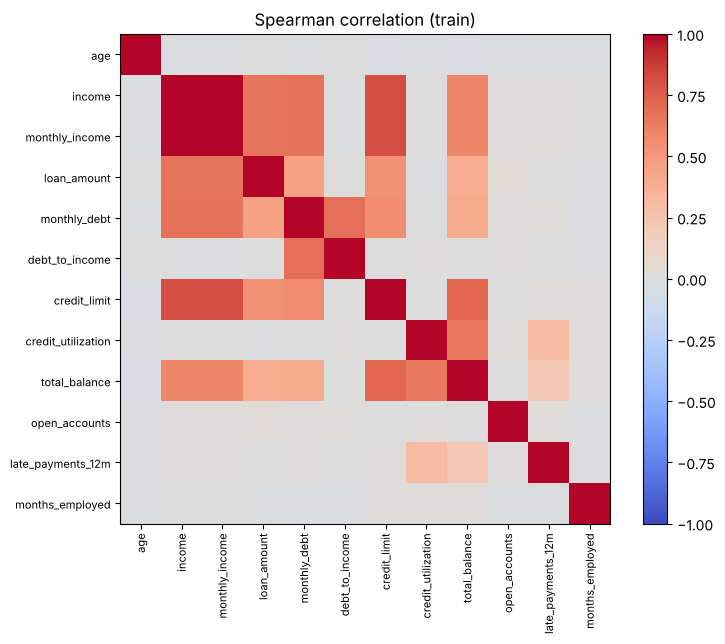

,level_0,level_1,rho
14,income,monthly_income,1.000000
18,income,credit_limit,0.805246
30,monthly_income,credit_limit,0.805246
80,credit_limit,total_balance,0.720298


In [6]:
num_cols_all = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c]) and c not in LEAK_OR_ID]
corr = X_train[num_cols_all].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5)); im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im); ax.set_title("Spearman correlation (train)"); plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
         .rename("rho").reset_index().query("abs(rho) > 0.7").sort_values("rho", key=abs, ascending=False))
pairs

`income` / `monthly_income` are the same quantity in two units, and `credit_limit` / `total_balance` are strongly related. The pipeline below includes a `CorrelationFilter` that learns which columns to drop **from the training fold only**.

## 5. Reusable pipeline code
- **Skewed non-negative numerics:** `log1p` → median impute + missing-indicator → standard scale
- **Other numerics:** median impute + missing-indicator → scale
- **Low-cardinality categoricals:** fill `"Missing"` → one-hot (rare and unseen levels pooled)
- **High-cardinality categoricals:** fill `"Missing"` → `TargetEncoder` (smoothed, cross-fitted inside `fit_transform`)
- **Correlation filter** on the encoded matrix, then the estimator.

In [7]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Drop later columns whose |Spearman rho| with an earlier kept column exceeds `threshold`.
    Learned in fit() from training data only."""
    def __init__(self, threshold=0.9):
        self.threshold = threshold
    def fit(self, X, y=None):
        df = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(df.columns.astype(str))
        corr = df.corr(method="spearman").abs().fillna(0)
        upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
        self.support_ = ~(upper > self.threshold).any(axis=0).to_numpy()
        self.dropped_ = list(self.feature_names_in_[~self.support_])
        return self
    def transform(self, X):
        check_is_fitted(self, "support_")
        return np.asarray(X)[:, self.support_]
    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "support_")
        return self.feature_names_in_[self.support_]


def split_columns(X, drop=(), high_card_threshold=15, skew_threshold=1.0):
    """Column roles are decided from the TRAINING frame only."""
    X = X.drop(columns=list(drop), errors="ignore")
    num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat = [c for c in X.columns if c not in num]
    high = [c for c in cat if X[c].nunique() > high_card_threshold]
    low = [c for c in cat if c not in high]
    skewed = [c for c in num if X[c].min() >= 0 and X[c].skew() > skew_threshold]
    plain = [c for c in num if c not in skewed]
    return dict(num_skewed=skewed, num_plain=plain, cat_low=low, cat_high=high)


def build_preprocessor(X_train, drop=(), corr_threshold=0.9, seed=SEED):
    roles = split_columns(X_train, drop)
    num_skewed = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                           ("scale", StandardScaler())])
    num_plain = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())])
    cat_low = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                 min_frequency=0.01, sparse_output=False))])
    cat_high = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                         ("target", TargetEncoder(target_type="binary", smooth="auto",
                                                  cv=5, shuffle=True, random_state=seed))])
    ct = ColumnTransformer([("num_skewed", num_skewed, roles["num_skewed"]),
                            ("num_plain", num_plain, roles["num_plain"]),
                            ("cat_low", cat_low, roles["cat_low"]),
                            ("cat_high", cat_high, roles["cat_high"])],
                           remainder="drop", verbose_feature_names_out=False)
    pre = Pipeline([("columns", ct), ("corr_filter", CorrelationFilter(corr_threshold))])
    pre.set_output(transform="pandas")
    return pre, roles


def build_pipeline(X_train, estimator, drop=(), **kw):
    pre, roles = build_preprocessor(X_train, drop, **kw)
    return Pipeline([("pre", pre), ("model", estimator)]), roles


lr = LogisticRegression(max_iter=2000, C=0.5)
pipe, roles = build_pipeline(X_train, lr, drop=LEAK_OR_ID)
roles

{'num_skewed': ['income',
  'monthly_income',
  'loan_amount',
  'monthly_debt',
  'credit_limit',
  'total_balance',
  'late_payments_12m',
  'months_employed'],
 'num_plain': ['age', 'debt_to_income', 'credit_utilization', 'open_accounts'],
 'cat_low': ['education', 'home_ownership', 'loan_purpose', 'region'],
 'cat_high': ['industry', 'postal_prefix']}

## 6. Proving it is leak-free
**(a)** A leaky column makes the score look great. **(b)** Fitting a target encoding on *all* rows makes a noise column look predictive. **(c)** Learned statistics should equal training-only statistics.

In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

# (a) leaky column left in vs dropped, same pipeline, training CV only
pipe_leaky, _ = build_pipeline(X_train, LogisticRegression(max_iter=2000, C=0.5), drop=["customer_id"])
auc_leaky = cross_validate(pipe_leaky, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"].mean()
auc_clean = cross_validate(pipe, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"].mean()
print(f"(a) CV ROC-AUC with leaky column: {auc_leaky:.3f}   without: {auc_clean:.3f}")

# (b) target-encode a pure-noise 500-level column: naive (all rows) vs correct (train only)
naive_map = pd.concat([X, y.rename("y")], axis=1).groupby("postal_prefix")["y"].mean()
naive_auc = roc_auc_score(y_test, X_test["postal_prefix"].map(naive_map))
te = TargetEncoder(target_type="binary", random_state=SEED).fit(X_train[["postal_prefix"]], y_train)
proper_auc = roc_auc_score(y_test, te.transform(X_test[["postal_prefix"]]).ravel())
print(f"(b) Test AUC of noise column  naive encoding on all rows: {naive_auc:.3f}   train-only encoding: {proper_auc:.3f} (0.5 = no signal)")

# (c) learned statistics come from the training set only
fitted = pipe.fit(X_train, y_train)
imp = fitted.named_steps["pre"].named_steps["columns"].named_transformers_["num_plain"].named_steps["impute"]
cols = roles["num_plain"]
assert np.allclose(imp.statistics_, X_train[cols].median().to_numpy())
print("(c) imputer medians equal training medians: OK")

(a) CV ROC-AUC with leaky column: 0.984   without: 0.869
(b) Test AUC of noise column  naive encoding on all rows: 0.692   train-only encoding: 0.506 (0.5 = no signal)
(c) imputer medians equal training medians: OK


## 7. Cross-validation on train, then one test evaluation

In [9]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
models = {"logreg": lr, "random_forest": rf}
rows = []
for name, est in models.items():
    p, _ = build_pipeline(X_train, est, drop=LEAK_OR_ID)
    r = cross_validate(p, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    rows.append(dict(model=name, cv_auc=r["test_roc_auc"].mean(), cv_auc_sd=r["test_roc_auc"].std(),
                     cv_pr_auc=r["test_average_precision"].mean()))
pd.DataFrame(rows).round(3)

,model,cv_auc,cv_auc_sd,cv_pr_auc
0,logreg,0.869,0.005,0.648
1,random_forest,0.854,0.009,0.595


In [10]:
final = {}
for name, est in models.items():
    p, _ = build_pipeline(X_train, est, drop=LEAK_OR_ID); p.fit(X_train, y_train)
    pr = p.predict_proba(X_test)[:, 1]; final[name] = p
    print(f"{name:14s} test ROC-AUC {roc_auc_score(y_test, pr):.3f} | PR-AUC {average_precision_score(y_test, pr):.3f}"
          f" | Brier {brier_score_loss(y_test, pr):.3f}   (prevalence {y_test.mean():.3f})")
fitted_pre = final["logreg"].named_steps["pre"]
print("\nCorrelation filter dropped:", fitted_pre.named_steps["corr_filter"].dropped_)
print("Final feature count:", len(fitted_pre.get_feature_names_out()))

logreg         test ROC-AUC 0.863 | PR-AUC 0.626 | Brier 0.105   (prevalence 0.189)


random_forest  test ROC-AUC 0.852 | PR-AUC 0.595 | Brier 0.146   (prevalence 0.189)

Correlation filter dropped: ['monthly_income', 'missingindicator_monthly_income']
Final feature count: 37


## 8. Feature importance
Three views, because each has a known weakness: mutual information (marginal, ignores interactions, biased up for many-level features), impurity importance from a random forest (biased toward high-cardinality / continuous features), and **permutation importance on the held-out test set** at the level of raw input columns (model-based, honest about generalisation, but split across correlated features).

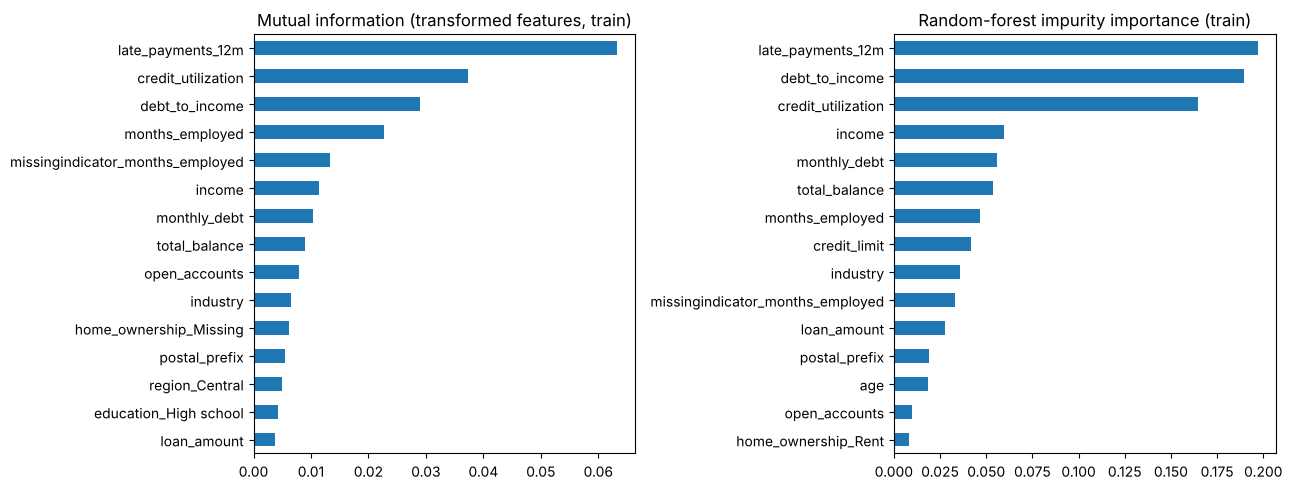

In [11]:
pre_fit, _ = build_preprocessor(X_train, LEAK_OR_ID)
Xt = pre_fit.fit_transform(X_train, y_train)
mi = pd.Series(mutual_info_classif(Xt, y_train, random_state=SEED), index=Xt.columns, name="mutual_info")
rf_full = final["random_forest"]
imp_tree = pd.Series(rf_full.named_steps["model"].feature_importances_,
                     index=rf_full.named_steps["pre"].get_feature_names_out(), name="rf_impurity")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mi.sort_values().tail(15).plot.barh(ax=axes[0], title="Mutual information (transformed features, train)")
imp_tree.sort_values().tail(15).plot.barh(ax=axes[1], title="Random-forest impurity importance (train)")
plt.tight_layout(); plt.show()

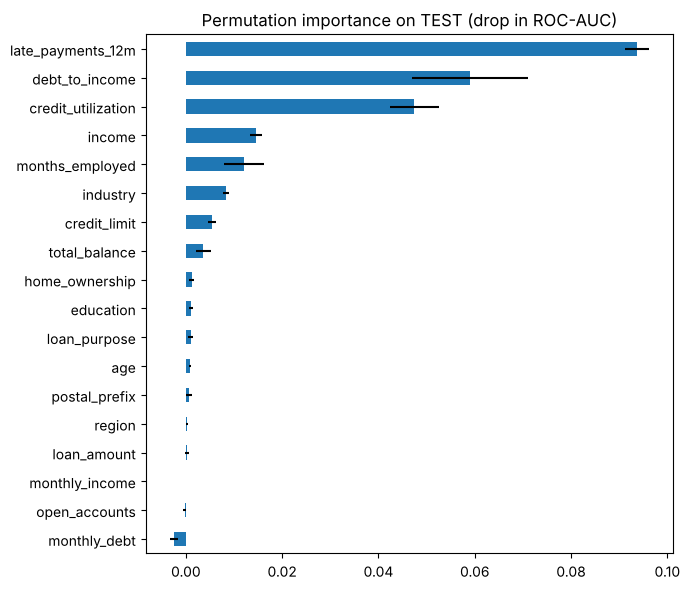

MI top-6 : ['late_payments_12m', 'credit_utilization', 'debt_to_income', 'months_employed', 'missingindicator_months_employed', 'income']
RF  top-6: ['late_payments_12m', 'debt_to_income', 'credit_utilization', 'income', 'monthly_debt', 'total_balance']


,mean,sd
late_payments_12m,0.0938,0.0025
debt_to_income,0.0591,0.0120
credit_utilization,0.0475,0.0051
income,0.0145,0.0013
months_employed,0.0120,0.0042
industry,0.0083,0.0007
credit_limit,0.0054,0.0009
total_balance,0.0036,0.0016
home_ownership,0.0012,0.0006
education,0.0010,0.0004


In [12]:
perm = permutation_importance(final["random_forest"], X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=SEED, n_jobs=-1)
perm_s = pd.DataFrame({"mean": perm.importances_mean, "sd": perm.importances_std}, index=X_test.columns)
perm_s = perm_s.drop(index=LEAK_OR_ID).sort_values("mean")
perm_s["mean"].plot.barh(xerr=perm_s["sd"], figsize=(7, 6), title="Permutation importance on TEST (drop in ROC-AUC)")
plt.tight_layout(); plt.show()
print("MI top-6 :", list(mi.sort_values(ascending=False).index[:6]))
print("RF  top-6:", list(imp_tree.sort_values(ascending=False).index[:6]))
perm_s.sort_values("mean", ascending=False).round(4).head(10)

**Reading the results.** Late payments, debt-to-income and utilisation lead in all three views, so they are robust signals. `missingindicator_months_employed` ranks high in mutual information: missingness itself is informative here (defaulters omit employment history more often), which is why the imputers keep indicators. The pure-noise `postal_prefix` stays low everywhere, because the cross-fitted `TargetEncoder` does not let it memorise labels (compare section 6b). Importance is not causation, and correlated features share credit, so confirm with ablation before dropping or acting on any feature.

## 9. Persist and sanity-test the pipeline

In [13]:
joblib.dump(final["logreg"], "credit_pipeline.joblib")
loaded = joblib.load("credit_pipeline.joblib")
assert np.allclose(loaded.predict_proba(X_test)[:, 1], final["logreg"].predict_proba(X_test)[:, 1])

edge = X_test.head(5).copy()
edge.loc[edge.index[0], "industry"] = "IND_NEW"            # unseen category
edge.loc[edge.index[1], ["income", "monthly_income", "education"]] = np.nan   # missing values
edge.loc[edge.index[2], "home_ownership"] = "Boat"          # unseen low-cardinality level
print(loaded.predict_proba(edge)[:, 1].round(3))
assert np.isfinite(loaded.predict_proba(edge)).all()
print("Round-trip and edge-case checks passed.")

[0.068 0.04  0.297 0.002 0.078]
Round-trip and edge-case checks passed.


### Reuse checklist
- Call `build_pipeline(X_train, estimator, drop=[...ids and leaks...])` on any tabular frame; column roles are inferred from the training frame.
- Always `fit` on training data only and call `cross_validate` on the **pipeline**, never on pre-transformed arrays.
- Swap `DATA_SOURCE` or the estimator; keep the split-first order and the explicit drop list.
- Next steps for production: time-based split, calibration check, monitoring of input drift and missingness rates.